# 01 Setup

---

In [1]:
import os
import zipfile

# 1. Clone only if the MNIST-JPG folder doesn't exist yet
if not os.path.exists("MNIST-JPG") and not os.path.exists("/content/MNIST-JPG"):
    print("Cloning repository...")
    !git clone https://github.com/teavanist/MNIST-JPG.git
else:
    print("Repository already exists. Skipping clone.")

# 2. Locate repo directory (works in Colab /content or local folder)
repo_dir = "MNIST-JPG" if os.path.exists("MNIST-JPG") else "/content/MNIST-JPG"

# 3. Unzip only if the extracted 'data' folder doesn't exist yet
data_dir = os.path.join(repo_dir, "data")
zip_path = os.path.join(repo_dir, "MNIST Dataset JPG format.zip")

if not os.path.exists(data_dir):
    print("Unzipping data...")
    os.makedirs(data_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
else:
    print("Data already unzipped. Skipping unzip.")


Cloning repository...
Cloning into 'MNIST-JPG'...
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 29 (delta 7), reused 27 (delta 7), pack-reused 1 (from 1)
Receiving objects: 100% (29/29), 17.53 MiB | 9.33 MiB/s, done.
Resolving deltas: 100% (7/7), done.
'MNIST Dataset JPG format.zip'	 mnist_jpg.py   README.md
Unzipping data...


# 02 Making Familiar with the Dataset Structure
1. structure
2. scale
3. balance
4. visual variety
5. technicals properties

## 1. Map Directory Structure

Here, we locate and explore the base folder structures of the unzipped dataset to verify the overall layout of training and testing data splits.

In [2]:
# Dynamically locate dataset path (works both in Colab and local laptop)
base_dir = os.path.abspath("MNIST-JPG/data/MNIST Dataset JPG format") if os.path.exists("MNIST-JPG/data/MNIST Dataset JPG format") else "/content/MNIST-JPG/data/MNIST Dataset JPG format"
print("Main folders: ", os.listdir(base_dir))


Main folders:  ['MNIST - JPG - testing', 'MNIST - JPG - training']


In [3]:
train_path = os.path.join(base_dir, "MNIST - JPG - training")

train_folders = os.listdir(train_path) # Get the list of folders/items inside

train_folders.sort()
print("Folders inside the train directory:", train_folders)


Folders inside the train directory: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [4]:
test_path = os.path.join(base_dir, "MNIST - JPG - testing")

test_folders = os.listdir(test_path) # Get the list of folders/items inside

test_folders.sort()
print("Folders inside the test directory:", test_folders)


Folders inside the test directory: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [5]:
zero_folder = os.path.join(train_path, "0")

zero_images = os.listdir(zero_folder)

print(f"Number of images in the 0 folder: {len(zero_images)}")


Number of images in the 0 folder: 5923


In [ ]:
# Show first 10 sample image filenames
print(f"Total images in folder: {len(zero_images)}")
print(f"Sample filenames (first 10): {zero_images[:10]}")


In [7]:
one_folder = os.path.join(train_path, "1")

one_images = os.listdir(one_folder)

print(f"Number of images in the 1 folder: {len(one_images)}")


Number of images in the 1 folder: 6742


## 2. Class Balance




Below, we count the number of images in each class folder (0-9) to determine if there is any class imbalance in the training and testing portions of our dataset.

In [8]:
# The loop starts here

total_train_images = 0

for digit in train_folders:
    # 1. Create the full path to the specific digit folder (e.g., MNIST-JPG/data/train/0)
    train_digit_path = os.path.join(train_path, digit)

    # 2. Make sure it is actually a folder (this ignores hidden system files)
    if os.path.isdir(train_digit_path):
        # 3. List all files inside this specific folder and count them
        train_images_inside = os.listdir(train_digit_path)
        train_count = len(train_images_inside)
        total_train_images += train_count

        # 4. Print the result
        print(f"Train Folder '{digit}' has {train_count} images.")

Train Folder '0' has 5923 images.
Train Folder '1' has 6742 images.
Train Folder '2' has 5958 images.
Train Folder '3' has 6131 images.
Train Folder '4' has 5842 images.
Train Folder '5' has 5421 images.
Train Folder '6' has 5918 images.
Train Folder '7' has 6265 images.
Train Folder '8' has 5851 images.
Train Folder '9' has 5949 images.


In [9]:
# The loop starts here

total_test_images = 0

for digit in test_folders:
    # 1. Create the full path to the specific digit folder (e.g., MNIST-JPG/data/train/0)
    test_digit_path = os.path.join(test_path, digit)


    # 2. Make sure it is actually a folder (this ignores hidden system files)
    if os.path.isdir(test_digit_path):
        # 3. List all files inside this specific folder and count them
        test_images_inside = os.listdir(test_digit_path)
        test_count = len(test_images_inside)
        total_test_images += test_count

        # 4. Print the result
        print(f"Test Folder '{digit}' has {test_count} images.")

Test Folder '0' has 980 images.
Test Folder '1' has 1135 images.
Test Folder '2' has 1032 images.
Test Folder '3' has 1010 images.
Test Folder '4' has 982 images.
Test Folder '5' has 892 images.
Test Folder '6' has 958 images.
Test Folder '7' has 1028 images.
Test Folder '8' has 974 images.
Test Folder '9' has 1009 images.


## 3. Measure the train/test split


In [13]:
print(f"Total number of images in the train folder: {total_train_images}")
print(f"Total number of images in the test folder: {total_test_images}")

Total number of images in the train folder: 60000
Total number of images in the test folder: 10000


## 4. Visual Inspection

We can load and plot single samples from each folder to visually inspect the pixel intensities, aspect ratios, and styles of the written digits.

## viewing single image

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Get image path
first_zero_image = zero_images[0]
image_path = os.path.join(zero_folder, first_zero_image)

print(f"Path of image is: {image_path}")

img = Image.open(image_path)
img_array = np.array(img)

print("Resolution (Height, Width):", img_array.shape)
print(f"The resolution of the image is: {img.size}")
print("Min pixel value (Black):", img_array.min())
print("Max pixel value (White):", img_array.max())

plt.imshow(img, cmap="gray")
plt.title(f"File: {first_zero_image}")
plt.axis('off') # Hides the axis grid
plt.show()



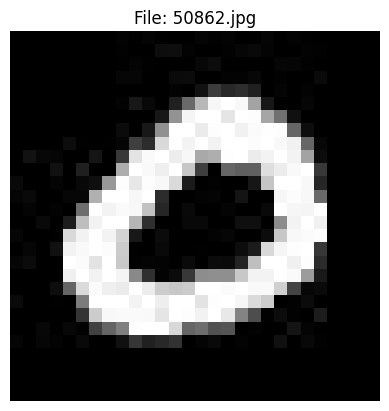

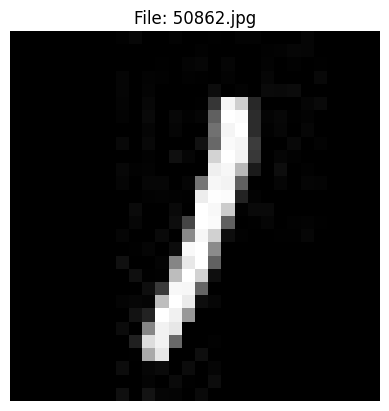

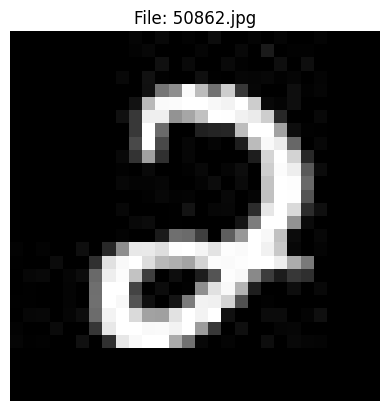

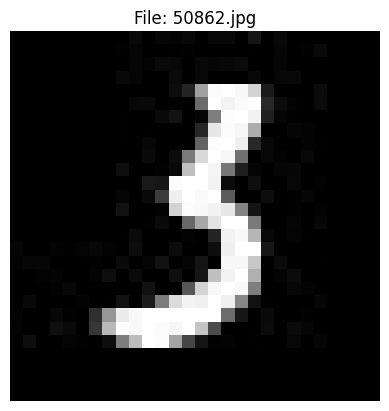

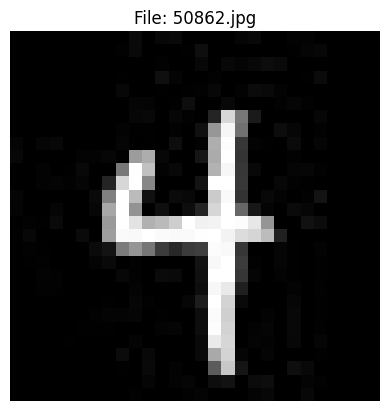

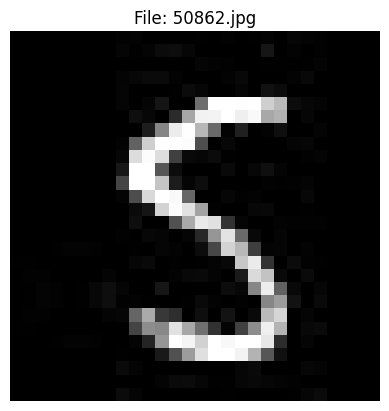

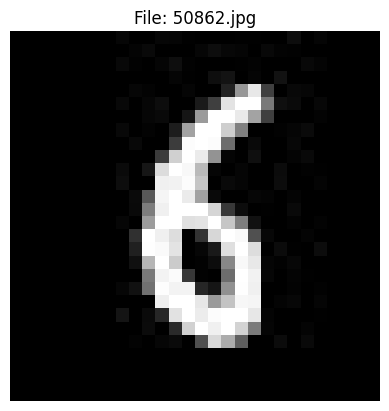

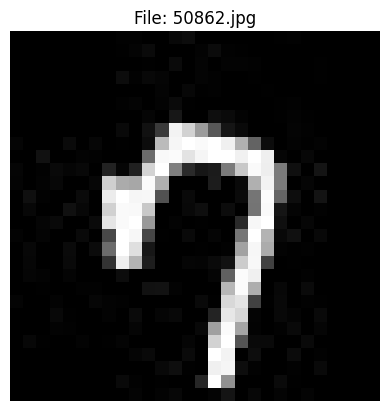

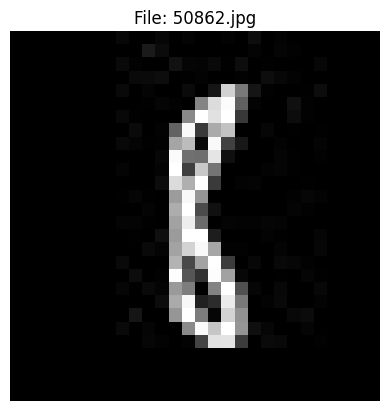

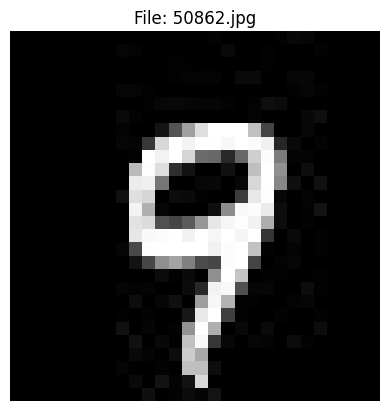

In [14]:
import numpy as np

for digit in train_folders:

  # Load specific image
  sample_img = Image.open(os.path.join(train_path, digit, os.listdir(os.path.join(train_path, digit))[0]))
  img_array = np.array(sample_img)

  plt.imshow(sample_img, cmap="gray")
  plt.title(f"Digit: {digit}")
  plt.axis('off') # Hides the axis grid
  plt.show()

# 03 Data Processing: CSV Backup

We aggregate the image file paths, their respective labels, and dataset splits into a single DataFrame, and export this index mapping to a structured CSV backup.

In [ ]:
import pandas as pd

base_dir = os.path.abspath("MNIST-JPG/data/MNIST Dataset JPG format") if os.path.exists("MNIST-JPG/data/MNIST Dataset JPG format") else "/content/MNIST-JPG/data/MNIST Dataset JPG format"
train_path = os.path.join(base_dir, "MNIST - JPG - training")
test_path = os.path.join(base_dir, "MNIST - JPG - testing")

csv_data = []

# Loop through both the 'train' and 'test' folders
for split in [train_path, test_path]:
    split_dir = os.path.join(base_dir, split)

    if not os.path.exists(split_dir):
        print(f"Warning: The folder {split_dir} does not exist. Check your paths.")
        continue

    # Loop through the digit folders (0, 1, 2... 9) inside the split folder
    for digit in os.listdir(split_dir):
        digit_dir = os.path.join(split_dir, digit)

        if os.path.isdir(digit_dir):
            # 3. Loop through every individual .jpg image inside the digit folder
            for img_file in os.listdir(digit_dir):
                if img_file.endswith('.jpg'):
                    # 4. Append a dictionary with your exact required column names
                    csv_data.append({
                        'jpg ID': img_file,
                        'digit': digit,
                        'train or test': split
                    })

# Convert the collected data into a pandas DataFrame (a table format)
df = pd.DataFrame(csv_data)

# Save it to a CSV file without the row index numbers
csv_filename = "mnist_backup.csv"
df.to_csv(csv_filename, index=False)

print(f"Success! {csv_filename} created with {len(df)} rows.")
print("\nFirst 5 rows of your new CSV:")
print(df.head())

# 04 Custom PyTorch Dataset

Here, we define a subclass of `torch.utils.data.Dataset` designed to read and normalize the JPEG files on demand, converting them into standard PyTorch Tensors.

In [ ]:
import os
import torch
from torch.utils.data import Dataset
from torchvision.io import read_image

class MnistDatasetNiki(Dataset):
  def __init__(self, directory_path):
    self.image_paths = []
    self.labels = []

    for digit in os.listdir(directory_path):
      digit_path = os.path.join(directory_path, digit)

      if os.path.isdir(digit_path):
        for img_file in os.listdir(digit_path):
          if img_file.endswith('.jpg'):
            # Store the full address of the image and its integer label
            self.image_paths.append(os.path.join(digit_path, img_file))
            self.labels.append(int(digit))

  def __len__(self):
    # return total count of collected images
    return len(self.image_paths)

  def __getitem__(self, idx):
    img_path = self.image_paths[idx]
    label = self.labels[idx]
    # Convert the JPG directly into a PyTorch Tensor
    # torchvision's read_image outputs a tensor of shape [Channels, Height, Width]
    # We convert it to a float and divide by 255.0 to scale the pixels from 0-255 down to 0.0-1.0
    image_tensor = read_image(img_path).float() / 255.0
    return (image_tensor, label)


### 05 Testing the Custom Dataset
We initialize the custom dataset object and verify that the indexing methods and output formats align perfectly with PyTorch expectations.

In [ ]:
train_path = os.path.join(base_dir, "MNIST - JPG - training") if "base_dir" in globals() else os.path.abspath("MNIST-JPG/data/MNIST Dataset JPG format/MNIST - JPG - training")

my_train_dataset = MnistDatasetNiki(directory_path=train_path)

# Test __len__
print(f"Total items in dataset: {len(my_train_dataset)}")

# Test __getitem__ (fetching the image at index 0)
first_tensor, first_label = my_train_dataset[0]

print(f"Output tuple format: ({type(first_tensor)}, {type(first_label)})")
print(f"Tensor shape: {first_tensor.shape}")
print(f"Label value: {first_label}")